In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from pathlib import Path

import xema

# Monthly national CPI by subclass (INE table 50905; the brief's 50937 is the annual one)
cpi = xema.download_cpi().set_index("date")
print(cpi.shape, cpi.index.min().date(), cpi.index.max().date(), cpi.isna().sum().sum())
# known values: olive oil +54.6 % and general CPI +3.1 % in December 2023
print(cpi.loc["2023-12-01", ["olive_oil_yoy", "general_yoy"]].to_dict())


(288, 8) 2002-01-01 2025-12-01 0
{'olive_oil_yoy': 54.6, 'general_yoy': 3.1}


In [2]:
# Rain in Catalonia: 10 XEMA stations (variable 1300, daily precipitation) in the
# agricultural comarques: Segria, Garrigues, Priorat, Baix Ebre, Tarragones
cat_stations = ["VK", "VH", "WK", "UM", "D1", "WJ", "U7", "DB", "VQ", "DK"]
cat = {}
for st in cat_stations:
    dd = xema.download_daily(st, "1300", "2002-01-01", "2025-12-31").set_index("date")["value"]
    mm = dd.resample("MS").agg(["sum", "count"])
    cat[st] = mm["sum"].where(mm["count"] >= 25)  # drop months with too few days
rain_cat = pd.DataFrame(cat).mean(axis=1)  # mean monthly total over the stations (mm)

# Rain in Andalusia (olive area): Open-Meteo reanalysis grid points near Jaen and Cordoba
sites = {"jaen": (37.77, -3.79), "cordoba": (37.89, -4.78)}
andalusia = {}
for name, (lat, lon) in sites.items():
    dd = xema.download_rain_openmeteo(name, lat, lon, "2002-01-01", "2025-12-31")
    andalusia[name] = dd.set_index("date")["value"].resample("MS").sum()
rain_and = pd.DataFrame(andalusia).mean(axis=1)

print(len(rain_cat), rain_cat.isna().sum(), rain_and.isna().sum())
print(pd.DataFrame({"Catalonia": rain_cat, "Andalusia": rain_and})
      .resample("YS").sum().round(0).rename(lambda d: d.year).T.to_string())


288 0 0
date        2002   2003   2004   2005   2006   2007   2008   2009   2010   2011   2012   2013   2014   2015   2016   2017   2018   2019   2020   2021   2022   2023   2024   2025
Catalonia  419.0  597.0  407.0  433.0  343.0  381.0  539.0  420.0  428.0  428.0  410.0  518.0  547.0  369.0  404.0  313.0  598.0  352.0  586.0  470.0  358.0  285.0  567.0  516.0
Andalusia  532.0  642.0  493.0  269.0  583.0  484.0  614.0  642.0  933.0  534.0  519.0  583.0  526.0  384.0  578.0  371.0  758.0  380.0  454.0  463.0  519.0  348.0  605.0  719.0


In [3]:
def acc_anomaly(rain, months):
    # rain accumulated over the last `months` months, standardised per calendar month
    # (a simple SPI-like index: negative = drier than usual)
    acc = rain.rolling(months).sum()
    g = acc.groupby(acc.index.month)
    return (acc - g.transform("mean")) / g.transform("std")


z12 = pd.DataFrame({"Andalusia": acc_anomaly(rain_and, 12),
                    "Catalonia": acc_anomaly(rain_cat, 12)})
z24 = pd.DataFrame({"Andalusia": acc_anomaly(rain_and, 24),
                    "Catalonia": acc_anomaly(rain_cat, 24)})
print(z24.loc["2023-12-01"].round(2).to_dict(), z12.loc["2023-12-01"].round(2).to_dict())


{'Andalusia': -1.02, 'Catalonia': -2.12} {'Andalusia': -1.32, 'Catalonia': -1.73}


In [4]:
from scipy import stats


def hydro_year_rain(rain, first=2003, last=2025):
    # rain total of the hydrological year: October (y - 1) to September (y), in mm
    return pd.Series({y: rain.loc[f"{y - 1}-10-01":f"{y}-09-01"].sum()
                      for y in range(first, last + 1)})


annual = pd.DataFrame({"rain_and": hydro_year_rain(rain_and),
                       "rain_cat": hydro_year_rain(rain_cat)})
for key in ("and", "cat"):
    r = annual[f"rain_{key}"]
    annual[f"z_{key}"] = (r - r.mean()) / r.std()  # anomaly of each year, 2003-2025
# the harvest of year y is in Nov (y) - Feb (y + 1): the price reaction is read in December
annual["price_dec"] = [cpi.loc[f"{y}-12-01", "olive_oil_yoy"] for y in annual.index]
print(annual.round(2).to_string())

rows = []
for key, region in (("and", "Andalusia"), ("cat", "Catalonia")):
    r, p = stats.pearsonr(annual[f"z_{key}"], annual["price_dec"])
    rs, ps = stats.spearmanr(annual[f"z_{key}"], annual["price_dec"])
    rows.append({"rain": region, "n": len(annual), "pearson_r": round(r, 2),
                 "p": round(p, 3), "spearman_r": round(rs, 2), "p_spearman": round(ps, 3)})
print(pd.DataFrame(rows).to_string(index=False))


      rain_and  rain_cat  z_and  z_cat  price_dec
2003    609.35    494.23   0.47   0.62        6.5
2004    678.90    530.52   0.93   1.05       14.0
2005    255.50    298.36  -1.90  -1.69       26.5
2006    468.15    470.75  -0.48   0.34       -2.6
2007    613.10    348.00   0.49  -1.10      -10.4
2008    531.45    487.14  -0.05   0.54       -2.5
2009    466.15    481.01  -0.49   0.47       -5.6
2010    946.55    449.55   2.73   0.09       -7.5
2011    711.60    358.30   1.15  -0.98        0.8
2012    385.65    386.95  -1.03  -0.64       18.0
2013    754.80    560.68   1.44   1.40        3.4
2014    455.70    507.31  -0.56   0.78       -4.0
2015    470.40    460.92  -0.46   0.23       26.5
2016    450.25    329.89  -0.60  -1.32       -2.9
2017    492.55    411.63  -0.32  -0.35       10.9
2018    670.70    393.91   0.88  -0.56      -15.5
2019    393.45    427.18  -0.98  -0.17      -11.4
2020    479.60    647.98  -0.40   2.43       -4.2
2021    464.55    452.21  -0.50   0.13       26.7


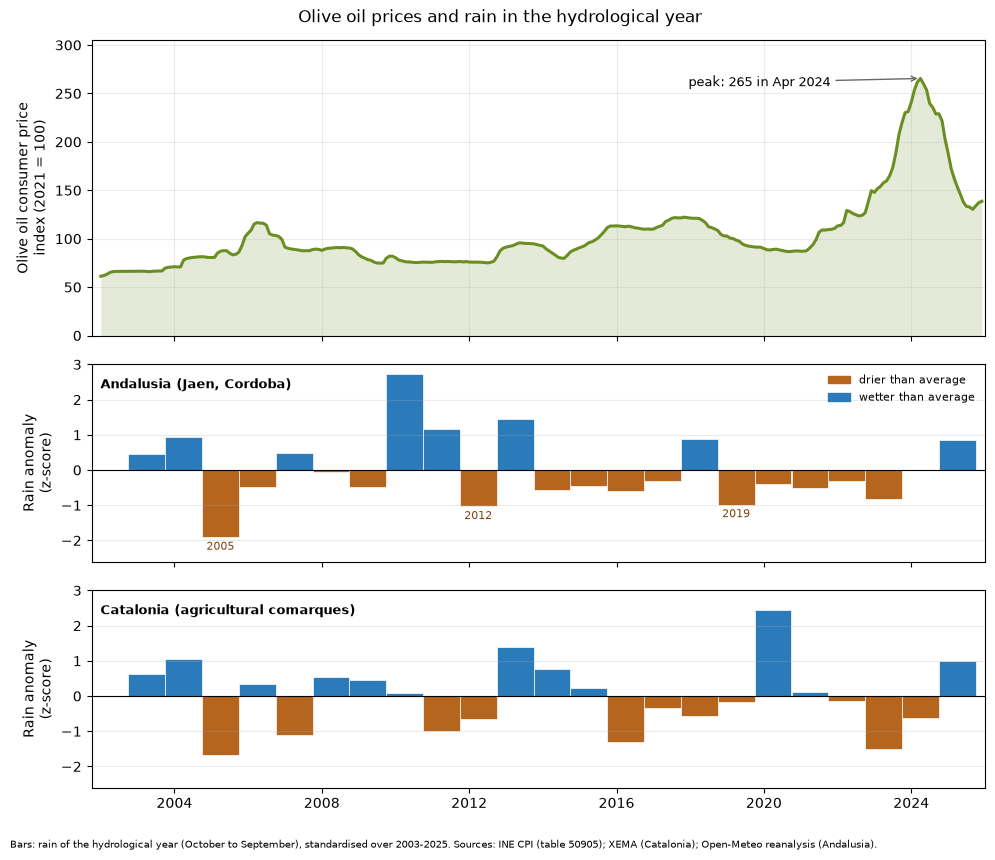

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(10, 8.6), sharex=True,
                         height_ratios=[1.5, 1, 1])
starts = [pd.Timestamp(f"{y - 1}-10-01") for y in annual.index]  # start of each hydrological year

ax = axes[0]
idx = cpi["olive_oil_index"]
ax.fill_between(idx.index, idx, color="olivedrab", alpha=0.18, lw=0)
ax.plot(idx.index, idx, color="olivedrab", lw=2.2)
ax.set_ylabel("Olive oil consumer price\nindex (2021 = 100)")
ax.set_ylim(0, idx.max() * 1.15)
top = idx.idxmax()
ax.annotate(f"peak: {idx.max():.0f} in {top:%b %Y}", xy=(top, idx.max()),
            xytext=(top - pd.Timedelta(days=2300), idx.max() * 0.97), fontsize=9,
            arrowprops=dict(arrowstyle="->", color="dimgrey"))
ax.grid(alpha=0.25)

for ax, key, region in ((axes[1], "z_and", "Andalusia (Jaen, Cordoba)"),
                        (axes[2], "z_cat", "Catalonia (agricultural comarques)")):
    z = annual[key]
    ax.bar(starts, z, width=365, align="edge",
           color=np.where(z < 0, "#b5651d", "#2b7bba"), edgecolor="white", linewidth=0.5)
    ax.axhline(0, color="black", lw=0.8)
    ax.set_ylim(-2.6, 3.0)
    ax.set_ylabel("Rain anomaly\n(z-score)")
    ax.text(0.01, 0.93, region, transform=ax.transAxes, fontsize=9, va="top",
            fontweight="bold")
    ax.grid(alpha=0.25, axis="y")
for y in annual["z_and"].nsmallest(3).index:  # label the three driest years in Andalusia
    axes[1].text(pd.Timestamp(f"{y - 1}-10-01") + pd.Timedelta(days=182), annual.loc[y, "z_and"] - 0.12,
                 str(y), ha="center", va="top", fontsize=8, color="#7a4313")
axes[1].legend(handles=[Patch(color="#b5651d", label="drier than average"),
                        Patch(color="#2b7bba", label="wetter than average")],
               loc="upper right", fontsize=8, frameon=False)
axes[2].set_xlim(pd.Timestamp("2001-10-01"), pd.Timestamp("2026-01-01"))

fig.suptitle("Olive oil prices and rain in the hydrological year")
fig.text(0.01, 0.005,
         "Bars: rain of the hydrological year (October to September), standardised over "
         "2003-2025. Sources: INE CPI (table 50905); XEMA (Catalonia); Open-Meteo "
         "reanalysis (Andalusia).", fontsize=7, ha="left")
fig.tight_layout(rect=(0, 0.03, 1, 1))

out = Path("..") / "figures" / "Gabri"
out.mkdir(parents=True, exist_ok=True)
fig.savefig(out / "olive_oil_vs_drought.png", dpi=200)
fig.savefig(out / "olive_oil_vs_drought.svg")


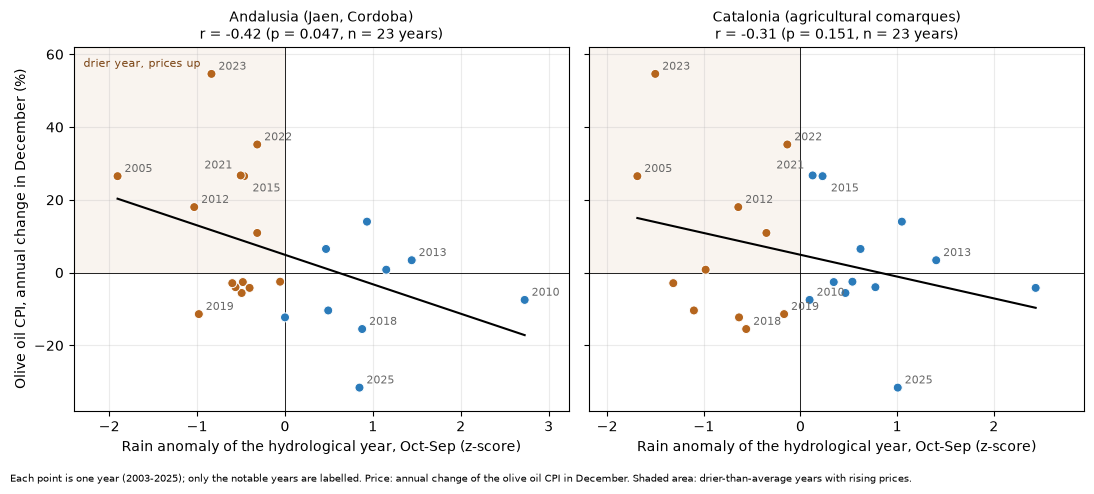

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.9), sharey=True)
# label only the notable years: the four driest in Andalusia, large price changes, extreme rain
notable = set(annual["z_and"].nsmallest(4).index) | set(annual.index[annual["price_dec"].abs() >= 15]) \
    | set(annual.index[annual["z_and"].abs() >= 1.4]) | {2010}
offsets = {2015: (6, -11), 2021: (-6, 5)}  # these two years overlap otherwise
for ax, key, region in ((axes[0], "z_and", "Andalusia (Jaen, Cordoba)"),
                        (axes[1], "z_cat", "Catalonia (agricultural comarques)")):
    x, y = annual[key], annual["price_dec"]
    ax.set_xlim(x.min() - 0.5, x.max() + 0.5)
    ax.set_ylim(-38, 62)
    ax.fill_between([ax.get_xlim()[0], 0], 0, 62, color="#b5651d", alpha=0.07, lw=0)  # drier, prices up
    ax.scatter(x, y, s=42, color=np.where(x < 0, "#b5651d", "#2b7bba"), edgecolor="white",
               linewidth=0.7, zorder=3)
    for yr in notable:
        dx, dy = offsets.get(yr, (5, 3))
        ax.annotate(str(yr), (x[yr], y[yr]), xytext=(dx, dy), textcoords="offset points",
                    fontsize=8, color="dimgrey", ha="right" if dx < 0 else "left")
    slope, intercept = np.polyfit(x, y, 1)
    xs = np.array([x.min(), x.max()])
    ax.plot(xs, intercept + slope * xs, color="black", lw=1.5)
    ax.axhline(0, color="black", lw=0.6)
    ax.axvline(0, color="black", lw=0.6)
    r, p = stats.pearsonr(x, y)
    ax.set_title(f"{region}\nr = {r:.2f} (p = {p:.3f}, n = {len(x)} years)", fontsize=10)
    ax.set_xlabel("Rain anomaly of the hydrological year, Oct-Sep (z-score)")
    ax.grid(alpha=0.25)
axes[0].set_ylabel("Olive oil CPI, annual change in December (%)")
axes[0].text(0.02, 0.97, "drier year, prices up", transform=axes[0].transAxes, va="top",
             fontsize=8, color="#7a4313")
fig.text(0.01, 0.005,
         "Each point is one year (2003-2025); only the notable years are labelled. Price: "
         "annual change of the olive oil CPI in December. Shaded area: drier-than-average "
         "years with rising prices.", fontsize=7, ha="left")
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(out / "olive_oil_rain_vs_price_scatter.png", dpi=200)
fig.savefig(out / "olive_oil_rain_vs_price_scatter.svg")


   window      rain            price  lag_of_min_r  min_r  r_lag0
12 months Andalusia        Olive oil             7  -0.35   -0.21
12 months Andalusia      Fresh fruit            13  -0.26    0.09
12 months Andalusia Fresh vegetables            14  -0.19   -0.12
12 months Catalonia        Olive oil             3  -0.29   -0.28
12 months Catalonia      Fresh fruit             8  -0.23    0.17
12 months Catalonia Fresh vegetables            12  -0.13    0.02
24 months Andalusia        Olive oil             0  -0.35   -0.35
24 months Andalusia      Fresh fruit             5  -0.17   -0.14
24 months Andalusia Fresh vegetables            21  -0.31   -0.21
24 months Catalonia        Olive oil             0  -0.29   -0.29
24 months Catalonia      Fresh fruit             5  -0.14   -0.05
24 months Catalonia Fresh vegetables             0  -0.09   -0.09


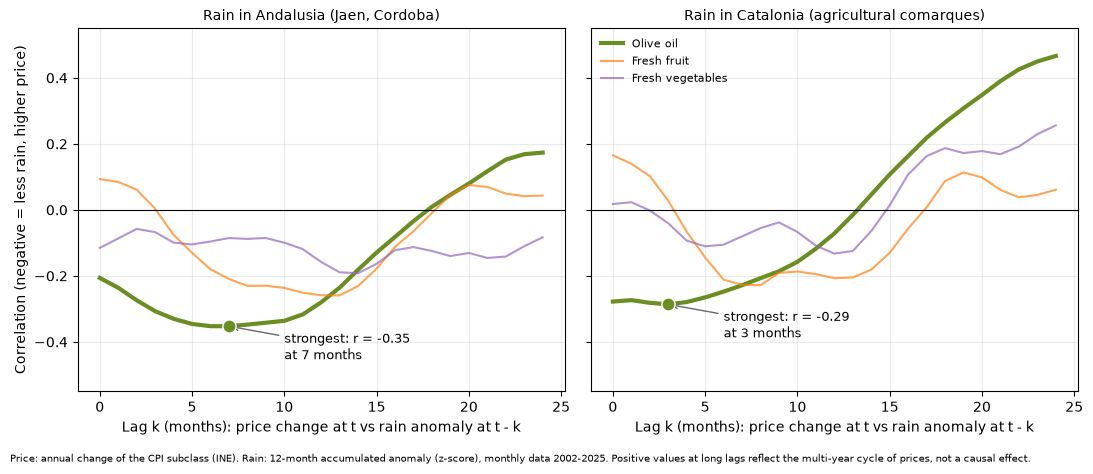

In [7]:
prices = {"Olive oil": cpi["olive_oil_yoy"], "Fresh fruit": cpi["fresh_fruit_yoy"],
          "Fresh vegetables": cpi["fresh_vegetables_yoy"]}
colors = {"Olive oil": "olivedrab", "Fresh fruit": "tab:orange", "Fresh vegetables": "tab:purple"}
lags = list(range(0, 25))


def lag_corr(price, z):
    # correlation between the price change at t and the rain anomaly at t - k
    return [price.corr(z.shift(k)) for k in lags]


fig, axes = plt.subplots(1, 2, figsize=(11, 4.7), sharey=True)
for ax, region in zip(axes, ["Andalusia (Jaen, Cordoba)", "Catalonia (agricultural comarques)"]):
    z = z12["Andalusia" if region.startswith("And") else "Catalonia"]
    for label, s in prices.items():
        r = lag_corr(s, z)
        main = label == "Olive oil"
        ax.plot(lags, r, color=colors[label], lw=3 if main else 1.5,
                alpha=1 if main else 0.7, label=label)
        if main:
            k = int(np.argmin(r))
            ax.scatter([k], [r[k]], s=90, color=colors[label], edgecolor="white", zorder=5)
            ax.annotate(f"strongest: r = {r[k]:.2f}\nat {k} months", xy=(k, r[k]),
                        xytext=(k + 3, r[k] - 0.1), fontsize=9,
                        arrowprops=dict(arrowstyle="->", color="dimgrey"))
    ax.axhline(0, color="black", lw=0.8)
    ax.set_ylim(-0.55, 0.55)
    ax.set_xlabel("Lag k (months): price change at t vs rain anomaly at t - k")
    ax.set_title(f"Rain in {region}", fontsize=10)
    ax.grid(alpha=0.25)
axes[0].set_ylabel("Correlation (negative = less rain, higher price)")
axes[1].legend(frameon=False, fontsize=8, loc="upper left")
fig.text(0.01, 0.005,
         "Price: annual change of the CPI subclass (INE). Rain: 12-month accumulated anomaly "
         "(z-score), monthly data 2002-2025. Positive values at long lags reflect the multi-year "
         "cycle of prices, not a causal effect.", fontsize=7, ha="left")
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(out / "olive_oil_lagged_correlation.png", dpi=200)
fig.savefig(out / "olive_oil_lagged_correlation.svg")

rows = []
for window, zz in (("12 months", z12), ("24 months", z24)):
    for region in ["Andalusia", "Catalonia"]:
        for label, s in prices.items():
            r = lag_corr(s, zz[region])
            k = int(np.argmin(r))
            rows.append({"window": window, "rain": region, "price": label,
                         "lag_of_min_r": k, "min_r": round(r[k], 2), "r_lag0": round(r[0], 2)})
print(pd.DataFrame(rows).to_string(index=False))
